In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
DATASET_PATH = r"C:\ML PROJECT\DATASET\Segmentation"

print("Dataset path:", DATASET_PATH)
print("Folders:", os.listdir(DATASET_PATH))

Dataset path: C:\ML PROJECT\DATASET\Segmentation
Folders: ['Glioma', 'Meningioma', 'Pituitary tumor']


In [3]:
for folder in os.listdir(DATASET_PATH):
    folder_path = os.path.join(DATASET_PATH, folder)
    
    if os.path.isdir(folder_path):
        files = os.listdir(folder_path)
        
        images = [f for f in files if not f.endswith("_mask.png")]
        masks = [f for f in files if f.endswith("_mask.png")]
        
        print(f"\n{folder}")
        print("-" * 30)
        print("Total files :", len(files))
        print("MRI images  :", len(images))
        print("Masks       :", len(masks))


Glioma
------------------------------
Total files : 1108
MRI images  : 554
Masks       : 554

Meningioma
------------------------------
Total files : 1416
MRI images  : 708
Masks       : 708

Pituitary tumor
------------------------------
Total files : 1860
MRI images  : 930
Masks       : 930


In [4]:
for folder in os.listdir(DATASET_PATH):
    folder_path = os.path.join(DATASET_PATH, folder)

    if not os.path.isdir(folder_path):
        continue

    image_files = [
        f for f in os.listdir(folder_path)
        if f.endswith(".png") and not f.endswith("_mask.png")
    ]

    missing_masks = []

    for image_file in image_files:
        mask_file = image_file.replace(".png", "_mask.png")
        mask_path = os.path.join(folder_path, mask_file)

        if not os.path.exists(mask_path):
            missing_masks.append(image_file)

    print(f"\n{folder}")
    print("-" * 30)
    print("Images:", len(image_files))
    print("Missing masks:", len(missing_masks))

    if missing_masks:
        print("Missing:", missing_masks[:10])
    else:
        print("✅ All images have corresponding masks")


Glioma
------------------------------
Images: 554
Missing masks: 0
✅ All images have corresponding masks

Meningioma
------------------------------
Images: 708
Missing masks: 0
✅ All images have corresponding masks

Pituitary tumor
------------------------------
Images: 930
Missing masks: 0
✅ All images have corresponding masks


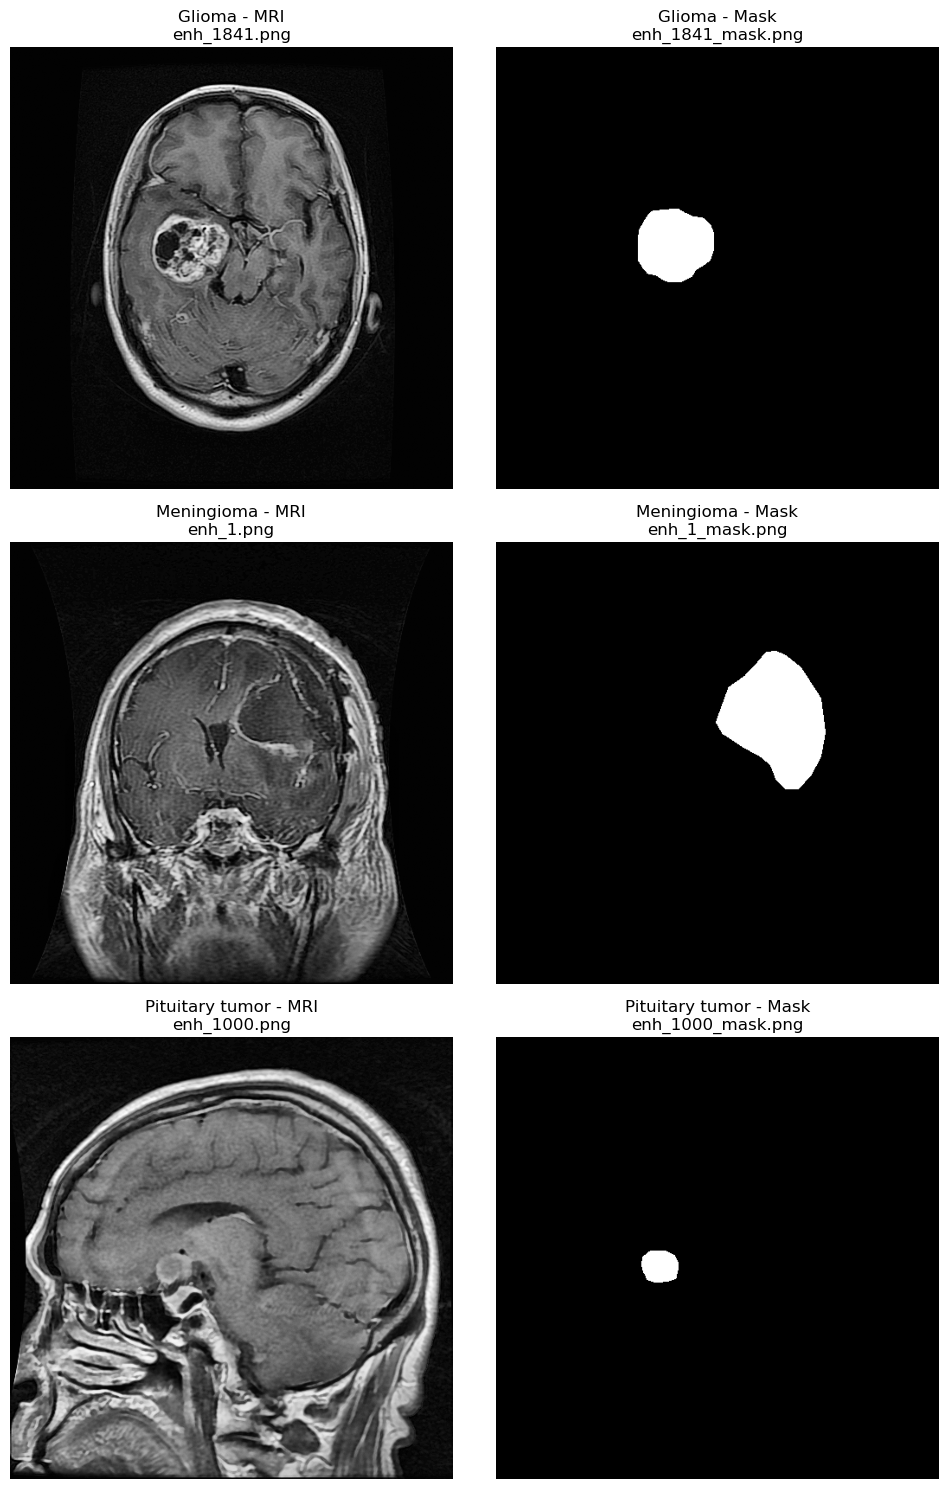

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(10, 15))

for row, folder in enumerate(["Glioma", "Meningioma", "Pituitary tumor"]):
    
    folder_path = os.path.join(DATASET_PATH, folder)
    
    # Get MRI images only
    image_files = [
        f for f in os.listdir(folder_path)
        if f.endswith(".png") and not f.endswith("_mask.png")
    ]
    
    # Take the first image
    image_file = image_files[0]
    mask_file = image_file.replace(".png", "_mask.png")
    
    # Full paths
    image_path = os.path.join(folder_path, image_file)
    mask_path = os.path.join(folder_path, mask_file)
    
    # Load images
    image = Image.open(image_path)
    mask = Image.open(mask_path)
    
    # Display MRI
    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(f"{folder} - MRI\n{image_file}")
    axes[row, 0].axis("off")
    
    # Display mask
    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(f"{folder} - Mask\n{mask_file}")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()